In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("/content/Online Retail.xlsx")

In [17]:
print(df.head())
print(df.shape)
print(df.info())
print(df.isnull().sum())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
(541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------      

In [18]:
# Remove rows without customer IDs
df = df.dropna(subset=["CustomerID"])

# Remove cancelled invoices
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

# Keep valid purchase quantities and prices
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# Calculate transaction amount
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

# Set the reference date one day after the last transaction
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM
rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate",
             lambda x: (reference_date - x.max()).days),

    Frequency=("InvoiceNo", "nunique"),

    Monetary=("TotalAmount", "sum")
)

print(rfm.head())
print(rfm.describe())

            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40
           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2054.266460
std     100.014169     7.697998    8989.230441
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     307.415000
50%      51.000000     2.000000     674.485000
75%     142.000000     5.000000    1661.740000
max     374.000000   209.000000  280206.020000


In [19]:
from sklearn.preprocessing import StandardScaler

# Reduce skewness
rfm_log = np.log1p(rfm)

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)

print(X_scaled.shape)

(4338, 3)


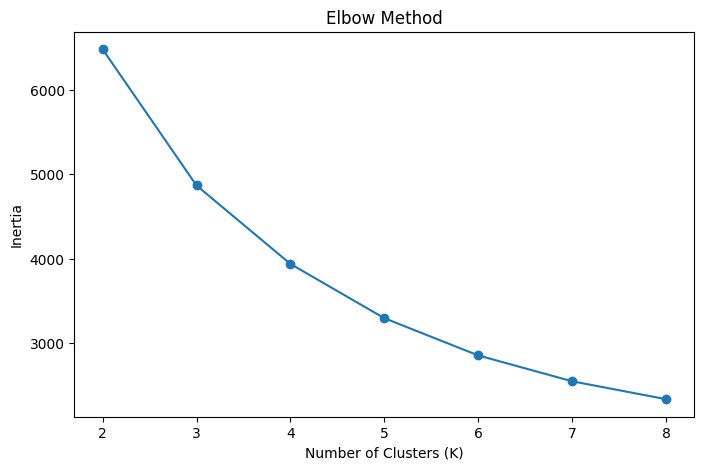

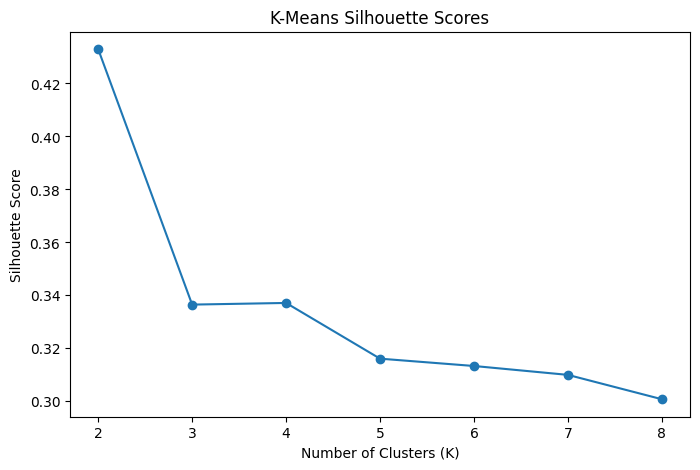

In [20]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Scores")
plt.show()

In [21]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print(rfm["KMeans_Cluster"].value_counts().sort_index())

KMeans_Cluster
0     837
1     716
2    1173
3    1612
Name: count, dtype: int64


In [22]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.7,
    min_samples=10
)

rfm["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print(rfm["DBSCAN_Cluster"].value_counts().sort_index())

DBSCAN_Cluster
-1      39
 0    4299
Name: count, dtype: int64


In [23]:
labels = rfm["DBSCAN_Cluster"].values

# Silhouette score requires at least 2 clusters,
# excluding noise, and fewer clusters than samples.
mask = labels != -1
valid_labels = labels[mask]

if (
    len(np.unique(valid_labels)) >= 2
    and len(valid_labels) > len(np.unique(valid_labels))
):
    score = silhouette_score(
        X_scaled[mask],
        valid_labels
    )
    print("DBSCAN Silhouette Score:", score)
else:
    print("Silhouette score is not defined for this result.")

Silhouette score is not defined for this result.


In [24]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("PCA shape:", X_pca.shape)

print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_
)

print(
    "Total variance retained:",
    pca.explained_variance_ratio_.sum()
)

PCA shape: (4338, 2)
Explained variance ratio: [0.75102042 0.18759201]
Total variance retained: 0.9386124314129813


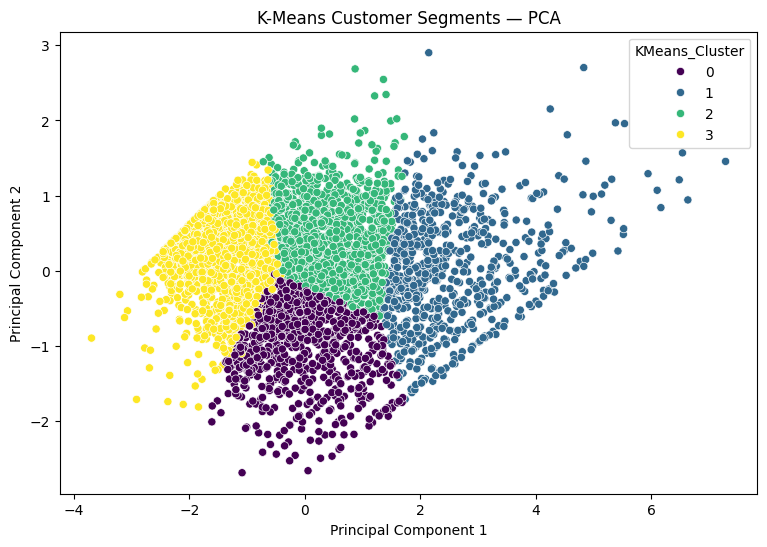

In [25]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=rfm["KMeans_Cluster"],
    palette="viridis",
    s=35
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Customer Segments — PCA")
plt.show()

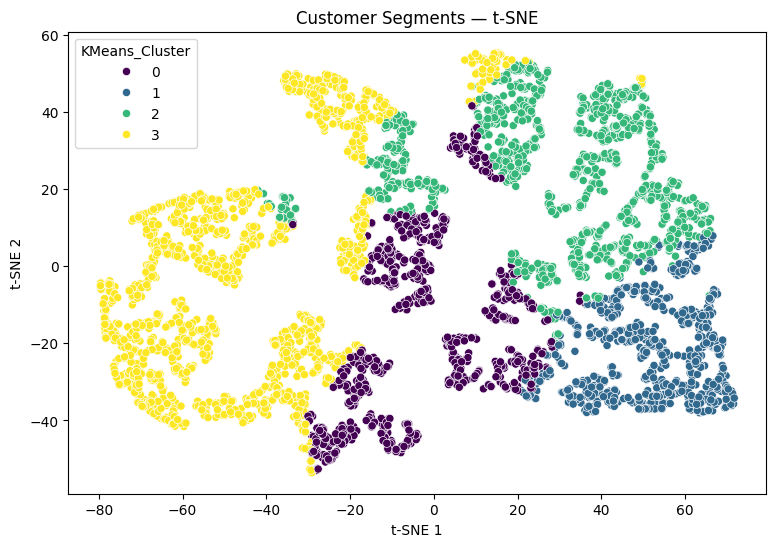

In [26]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=rfm["KMeans_Cluster"],
    palette="viridis",
    s=35
)

plt.title("Customer Segments — t-SNE")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.show()

In [14]:
persona_summary = rfm.groupby("KMeans_Cluster").agg(
    Customers=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

print(persona_summary)

                Customers  Avg_Recency  Avg_Frequency  Avg_Monetary
KMeans_Cluster                                                     
0                     837        18.12           2.15        551.82
1                     716        12.13          13.71       8074.27
2                    1173        71.08           4.08       1802.83
3                    1612       182.50           1.32        343.45
